# FICE Training Notebook

A comprehensive training notebook for the Fully Inductive Cardinality Estimation (FICE) model.

This notebook contains all the functionality from the training script organized into logical sections for better interactivity and experimentation.

## 1. Setup and Imports

Import all necessary libraries and set up the environment.

In [9]:
if "google.colab" in str(get_ipython()):
    google_drive = True  #@param {type:"boolean"} 
    # Install dependencies
    !bash /content/fully-inductive-cardinality-estimation/notebooks/colab_install.sh
else:
    google_drive = False

In [ ]:
import torch
import json
import random
import numpy as np
import os
import sys
import logging
from pathlib import Path
from datetime import datetime
import math
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# Ensure the fice package is in the Python path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
if google_drive:
    sys.path.append(os.path.abspath('/content/fully-inductive-cardinality-estimation/fice'))
    sys.path.append(os.path.abspath('/content/fully-inductive-cardinality-estimation'))

# Import project modules
import scripts.utils.helper as helper
import scripts.utils.config as config
import scripts.utils.metrics as metrics
import scripts.utils.plotting as plotting
from fice import datasets
from fice.models import FICE
import torch.nn.functional as F
from torch_geometric.loader import DataLoader

# Set up basic logging for this cell

print("All imports successful!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

All imports successful!
PyTorch version: 2.8.0
CUDA available: False


## 2. Configuration

Set up all training parameters and configuration.

In [ ]:
# Configuration
CONFIG = {
    # Data settings
    "data_root": "data/swdf/",
    "queries_root": "data/swdf_queries",

    # Training settings
    "epochs": 2,
    "batch_size": 1,
    "learning_rate": 1e-5,
    "weight_decay": 0.0,
    "train_ratio": 0.8,

    # Logging and saving settings
    "run_dir": "runs/",
    "log_dir": "logs/",
    "checkpoint_dir": "checkpoints/",
    "save_every": 5,
    "log_level": "INFO",

    # Other settings
    "seed": 42,
    "device": "auto",  # "auto", "cpu", or "cuda"
    "eval_every": 1,
    'DEBUG_num_queries': 10,  # Set to None to use all queries
}

config = CONFIG.copy()
config = config.load_config("cluster_config.json")

## 3. Setup Directories and Environment

Initialize project directories, timestamps, and logging.

In [12]:
# Setup directories

if google_drive:
  from google.colab import drive
  drive.mount('/content/drive')

root_project_folder = Path(os.path.abspath(os.path.join(os.getcwd(), "..")))
if google_drive:
  root_project_folder = Path('/content/fully-inductive-cardinality-estimation')

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

run_dir = root_project_folder / f"run_{timestamp}"
if google_drive:
  run_dir = Path("/content/drive/MyDrive") / f"run_{timestamp}"

run_dir.mkdir(parents=True, exist_ok=True)

config["data_root"] = root_project_folder / "data/swdf/"
config["queries_root"] = root_project_folder / "data/swdf_queries"
config["log_dir"] = run_dir / "logs/"
config["checkpoint_dir"] = run_dir / "checkpoints/"

# Set random seeds for reproducibility
helper.set_random_seeds(config["seed"])

# Setup device
device = helper.get_device(config["device"])

# Setup logging
log_dir = Path(config["log_dir"])
logger = helper.setup_logging(log_dir, config["log_level"])
for key, value in config.items():
    logger.info(f"  {key}: {value}")

logger.info(f"Project root: {root_project_folder}")
logger.info(f"Run directory: {run_dir}")
logger.info(f"Using device: {device}")
logger.info(f"Random seed: {config['seed']}")
logger.info(f"Log directory: {log_dir}")

2025-09-30 11:34:38,352 - fice_training - INFO -   data_root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf
2025-09-30 11:34:38,353 - fice_training - INFO -   queries_root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_queries
2025-09-30 11:34:38,353 - fice_training - INFO -   epochs: 5
2025-09-30 11:34:38,353 - fice_training - INFO -   batch_size: 1
2025-09-30 11:34:38,354 - fice_training - INFO -   learning_rate: 1e-05
2025-09-30 11:34:38,354 - fice_training - INFO -   weight_decay: 0.0
2025-09-30 11:34:38,355 - fice_training - INFO -   train_ratio: 0.8
2025-09-30 11:34:38,355 - fice_training - INFO -   log_dir: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs
2025-09-30 11:34:38,356 - fice_training - INFO -   checkpoint_dir: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/checkpoints
2025-09-30 11:34:38,356 - fice_training - INFO -   save_every: 5
2025-09-30 11:34:38,356 - fice_training - INFO -   log_level:

## 4. Data Loading

Load the graph dataset and verify its properties.

In [13]:
# Setup data directories
data_root = Path(config["data_root"])
queries_root = Path(config["queries_root"])
checkpoint_dir = Path(config["checkpoint_dir"])
checkpoint_dir.mkdir(parents=True, exist_ok=True)

logger.info(f"Data root: {data_root}")
logger.info(f"Queries root: {queries_root}")
logger.info(f"Checkpoint dir: {checkpoint_dir}")

# Load dataset
logger.info("Loading dataset...")
nt_path = data_root / "raw/swdf.nt"

if not nt_path.exists():
    raise FileNotFoundError(f"Dataset file not found: {nt_path}")

graph = datasets.NTDatasets(root=data_root, nt_path=nt_path)
graph = graph[0].to(device)

logger.info(f"Graph loaded successfully!")
logger.info(f"Number of nodes: {graph.num_nodes}")
logger.info(f"Number of edges: {graph.num_edges}")
logger.info(f"Node features shape: {graph.x.shape if hasattr(graph, 'x') and graph.x is not None else 'None'}")
logger.info(f"Edge indices shape: {graph.edge_index.shape}")
logger.info(f"Edge types shape: {graph.edge_type.shape if hasattr(graph, 'edge_type') and graph.edge_type is not None else 'None'}")

2025-09-30 11:34:38,366 - fice_training - INFO - Data root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf
2025-09-30 11:34:38,367 - fice_training - INFO - Queries root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_queries
2025-09-30 11:34:38,367 - fice_training - INFO - Checkpoint dir: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/checkpoints
2025-09-30 11:34:38,367 - fice_training - INFO - Loading dataset...
2025-09-30 11:34:38,374 - fice_training - INFO - Graph loaded successfully!
2025-09-30 11:34:38,374 - fice_training - INFO - Number of nodes: 76711
2025-09-30 11:34:38,374 - fice_training - INFO - Number of edges: 242256
2025-09-30 11:34:38,375 - fice_training - INFO - Node features shape: None
2025-09-30 11:34:38,375 - fice_training - INFO - Edge indices shape: torch.Size([2, 242256])
2025-09-30 11:34:38,375 - fice_training - INFO - Edge types shape: torch.Size([242256])
2025-09-30 11:34:38,367 - fice_training - INFO - Queries ro

## 5. Load Metadata

Load entity and relation mappings and occurrence data.

In [14]:
# Load metadata
logger.info("Loading metadata...")
entity_occurrences_path = data_root / "processed/swdf_entity_occurrences.json"
relation_occurrences_path = data_root / "processed/swdf_relation_occurrences.json"
entity_mapping_path = data_root / "processed/swdf_entity_to_id.json"
relation_mapping_path = data_root / "processed/swdf_relation_to_id.json"

with open(entity_occurrences_path, "r") as f:
    entity_occurrences = json.load(f)
with open(relation_occurrences_path, "r") as f:
    relation_occurrences = json.load(f)
with open(entity_mapping_path, "r") as f:
    entity_mapping = json.load(f)
with open(relation_mapping_path, "r") as f:
    relation_mapping = json.load(f)

logger.info("Metadata loaded successfully!")
logger.info(f"Entities with occurrences: {len(entity_occurrences)}")
logger.info(f"Relations with occurrences: {len(relation_occurrences)}")
logger.info(f"Entity mapping size: {len(entity_mapping)}")
logger.info(f"Relation mapping size: {len(relation_mapping)}")

2025-09-30 11:34:38,381 - fice_training - INFO - Loading metadata...
2025-09-30 11:34:38,417 - fice_training - INFO - Metadata loaded successfully!
2025-09-30 11:34:38,418 - fice_training - INFO - Entities with occurrences: 76711
2025-09-30 11:34:38,419 - fice_training - INFO - Relations with occurrences: 170
2025-09-30 11:34:38,420 - fice_training - INFO - Entity mapping size: 76711
2025-09-30 11:34:38,420 - fice_training - INFO - Relation mapping size: 170
2025-09-30 11:34:38,417 - fice_training - INFO - Metadata loaded successfully!
2025-09-30 11:34:38,418 - fice_training - INFO - Entities with occurrences: 76711
2025-09-30 11:34:38,419 - fice_training - INFO - Relations with occurrences: 170
2025-09-30 11:34:38,420 - fice_training - INFO - Entity mapping size: 76711
2025-09-30 11:34:38,420 - fice_training - INFO - Relation mapping size: 170


## 6. Load and Process Queries

Load queries and create train/test split.

In [15]:
# Load queries
logger.info("Loading queries...")
query_path = queries_root / "raw/Joined_Queries.json"

if not query_path.exists():
    raise FileNotFoundError(f"Queries file not found: {query_path}")

queries = datasets.NTQueries(
    root=queries_root,
    queries_path=query_path,
    entity_occurrences=entity_occurrences,
    relation_occurrences=relation_occurrences,
    global_entity_mapping=entity_mapping,
    global_relation_mapping=relation_mapping,
    device=device
)
logger.info(f"Queries loaded. Total queries: {len(queries)}")

# Process and filter queries
queries_list = list(queries)
queries_list = [q for q in queries_list if q.y.item() <= 30]
random.shuffle(queries_list)

if config['DEBUG_num_queries'] is not None:
    queries_list = queries_list[:config['DEBUG_num_queries']]
    logger.info(f"Using debug mode with {config['DEBUG_num_queries']} queries")

logger.info(f"Filtered queries (cardinality <= 30): {len(queries_list)}")

2025-09-30 11:34:38,425 - fice_training - INFO - Loading queries...
2025-09-30 11:34:38,455 - fice_training - INFO - Queries loaded. Total queries: 116645
2025-09-30 11:34:38,455 - fice_training - INFO - Queries loaded. Total queries: 116645
2025-09-30 11:34:42,839 - fice_training - INFO - Using debug mode with 20 queries
2025-09-30 11:34:42,840 - fice_training - INFO - Filtered queries (cardinality <= 30): 20
2025-09-30 11:34:42,839 - fice_training - INFO - Using debug mode with 20 queries
2025-09-30 11:34:42,840 - fice_training - INFO - Filtered queries (cardinality <= 30): 20


## 7. Create Data Split and Loaders

Split data into training and testing sets and create data loaders.

In [16]:
# Train-test split
train_size = int(len(queries_list) * config["train_ratio"])
test_size = len(queries_list) - train_size

train_queries = queries_list[:train_size]
test_queries = queries_list[train_size:]

logger.info(f"Dataset split:")
logger.info(f"  Total queries: {len(queries_list)}")
logger.info(f"  Train queries: {len(train_queries)} ({len(train_queries)/len(queries_list)*100:.1f}%)")
logger.info(f"  Test queries: {len(test_queries)} ({len(test_queries)/len(queries_list)*100:.1f}%)")
logger.info(f"  Train ratio: {config['train_ratio']}")

# Create data loaders
train_loader = DataLoader(
    dataset=train_queries,
    batch_size=config["batch_size"],
    shuffle=True
)
test_loader = DataLoader(
    dataset=test_queries,
    batch_size=1,  # Use batch_size=1 for evaluation
    shuffle=False
)

logger.info(f"Data loaders created:")
logger.info(f"  Train batches: {len(train_loader)}")
logger.info(f"  Test batches: {len(test_loader)}")

2025-09-30 11:34:42,844 - fice_training - INFO - Dataset split:
2025-09-30 11:34:42,844 - fice_training - INFO -   Total queries: 20
2025-09-30 11:34:42,845 - fice_training - INFO -   Train queries: 16 (80.0%)
2025-09-30 11:34:42,845 - fice_training - INFO -   Test queries: 4 (20.0%)
2025-09-30 11:34:42,846 - fice_training - INFO -   Train ratio: 0.8
2025-09-30 11:34:42,846 - fice_training - INFO - Data loaders created:
2025-09-30 11:34:42,846 - fice_training - INFO -   Train batches: 16
2025-09-30 11:34:42,847 - fice_training - INFO -   Test batches: 4
2025-09-30 11:34:42,844 - fice_training - INFO -   Total queries: 20
2025-09-30 11:34:42,845 - fice_training - INFO -   Train queries: 16 (80.0%)
2025-09-30 11:34:42,845 - fice_training - INFO -   Test queries: 4 (20.0%)
2025-09-30 11:34:42,846 - fice_training - INFO -   Train ratio: 0.8
2025-09-30 11:34:42,846 - fice_training - INFO - Data loaders created:
2025-09-30 11:34:42,846 - fice_training - INFO -   Train batches: 16
2025-09-30 

## 8. Model Initialization

Initialize the FICE model and optimizer.

In [17]:
# Initialize model
logger.info("Initializing model...")
model = FICE(data=graph)
model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

logger.info(f"Model initialized successfully!")
logger.info(f"Model: {model.__class__.__name__}")
logger.info(f"Total parameters: {total_params:,}")
logger.info(f"Trainable parameters: {trainable_params:,}")
logger.info(f"Model device: {next(model.parameters()).device}")

# Initialize optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"]

)

logger.info(f"Optimizer: {optimizer.__class__.__name__}")
logger.info(f"Learning rate: {config['learning_rate']}")
logger.info(f"Weight decay: {config['weight_decay']}")

2025-09-30 11:34:42,851 - fice_training - INFO - Initializing model...
2025-09-30 11:34:42,872 - fice_training - INFO - Model initialized successfully!
2025-09-30 11:34:42,873 - fice_training - INFO - Model: FICE
2025-09-30 11:34:42,873 - fice_training - INFO - Total parameters: 198,161
2025-09-30 11:34:42,874 - fice_training - INFO - Trainable parameters: 198,161
2025-09-30 11:34:42,875 - fice_training - INFO - Model device: cpu
2025-09-30 11:34:42,876 - fice_training - INFO - Optimizer: AdamW
2025-09-30 11:34:42,877 - fice_training - INFO - Learning rate: 1e-05
2025-09-30 11:34:42,878 - fice_training - INFO - Weight decay: 0.0
2025-09-30 11:34:42,872 - fice_training - INFO - Model initialized successfully!
2025-09-30 11:34:42,873 - fice_training - INFO - Model: FICE
2025-09-30 11:34:42,873 - fice_training - INFO - Total parameters: 198,161
2025-09-30 11:34:42,874 - fice_training - INFO - Trainable parameters: 198,161
2025-09-30 11:34:42,875 - fice_training - INFO - Model device: cpu


## 9. Training Setup

Initialize tracking variables and helper functions for training.

In [18]:
# Training metrics tracking
best_test_loss = float('inf')

train_losses = []
train_mse = []
train_mae = []
train_rmse = []
train_q_error = []
train_predictions_log = []
train_true_values_log = []

test_losses = []
test_mse = []
test_mae = []
test_rmse = []
test_q_error = []
test_predictions_log = []
test_true_values_log = []

# Helper function to convert tensors to numpy
def tensor_to_numpy(tensor):
    return tensor.detach().cpu().numpy().tolist()

logger.info("Training tracking variables initialized!")
logger.info(f"Starting training for {config['epochs']} epochs...")

2025-09-30 11:34:42,883 - fice_training - INFO - Training tracking variables initialized!
2025-09-30 11:34:42,884 - fice_training - INFO - Starting training for 5 epochs...
2025-09-30 11:34:42,884 - fice_training - INFO - Starting training for 5 epochs...


## 10. Training Loop

Main training loop with progress tracking and evaluation.

In [19]:
# Training loop
for epoch in range(config["epochs"]):
    # Training phase
    model.train()
    epoch_train_loss = 0.0
    num_train_batches = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{config['epochs']}",
        leave=False
    )

    epoch_train_predictions = []
    epoch_train_true_values = []
    epoch_train_predictions_log = []
    epoch_train_true_values_log = []

    for batch_idx, query_batch in enumerate(progress_bar):
        optimizer.zero_grad()

        # Forward pass
        query_batch = query_batch.to(device)
        log_cardinality_pred = model(batch=query_batch)
        log_cardinality_pred = log_cardinality_pred.to(torch.float32).to(device)

        log_true_cardinality = torch.log(query_batch.y.to(torch.float32).to(device))

        epoch_train_predictions_log.extend(tensor_to_numpy(log_cardinality_pred))
        epoch_train_true_values_log.extend(tensor_to_numpy(log_true_cardinality))

        # Compute loss
        loss = F.mse_loss(log_cardinality_pred, log_true_cardinality).to(device)

        # Backward pass
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item()
        num_train_batches += 1

        # Store predictions for analysis
        prediction = torch.exp(log_cardinality_pred)
        true_value = query_batch.y.to(torch.float32)

        epoch_train_predictions.extend(tensor_to_numpy(prediction))
        epoch_train_true_values.extend(tensor_to_numpy(true_value))

        # Update progress bar
        progress_bar.set_postfix({
            'loss': f"{loss.item():.4f}",
            'avg_loss': f"{epoch_train_loss/num_train_batches:.4f}"
        })

    epoch_avg_train_loss = epoch_train_loss / num_train_batches

    # Calculate training metrics
    mse = metrics.calculate_mse(epoch_train_predictions, epoch_train_true_values)
    mae = metrics.calculate_mae(epoch_train_predictions, epoch_train_true_values)
    rmse = np.sqrt(mse)
    q_error = metrics.calculate_q_error(epoch_train_predictions, epoch_train_true_values)

    train_losses.append(epoch_avg_train_loss)
    train_mse.append(mse)
    train_mae.append(mae)
    train_rmse.append(rmse)
    train_q_error.append(q_error)
    train_predictions_log.append(epoch_train_predictions_log)
    train_true_values_log.append(epoch_train_true_values_log)

    # Evaluation phase
    if (epoch + 1) % config["eval_every"] == 0:
        model.eval()
        epoch_test_loss = 0.0
        epoch_test_predictions = []
        epoch_test_true_values = []
        epoch_test_predictions_log = []
        epoch_test_true_values_log = []

        with torch.no_grad():
            for query_batch in tqdm(test_loader, desc="Evaluating", leave=False):
                # Forward pass
                query_batch = query_batch.to(device)

                log_cardinality_pred = model(batch=query_batch)
                log_cardinality_pred = log_cardinality_pred.to(torch.float32)
                log_true_cardinality = torch.log(query_batch.y.to(torch.float32))

                epoch_test_predictions_log.extend(tensor_to_numpy(log_cardinality_pred))
                epoch_test_true_values_log.extend(tensor_to_numpy(log_true_cardinality))

                # Compute loss
                loss = F.mse_loss(log_cardinality_pred, log_true_cardinality)
                epoch_test_loss += loss.item()

                # Store predictions for analysis
                prediction = torch.exp(log_cardinality_pred)
                true_value = query_batch.y.to(torch.float32)

                epoch_test_predictions.extend(tensor_to_numpy(prediction))
                epoch_test_true_values.extend(tensor_to_numpy(true_value))

        avg_test_loss = epoch_test_loss / len(test_loader)

        # Calculate test metrics
        mse = metrics.calculate_mse(epoch_test_predictions, epoch_test_true_values)
        mae = metrics.calculate_mae(epoch_test_predictions, epoch_test_true_values)
        rmse = np.sqrt(mse)
        q_error = metrics.calculate_q_error(epoch_test_predictions, epoch_test_true_values)

        test_losses.append(avg_test_loss)
        test_mse.append(mse)
        test_mae.append(mae)
        test_rmse.append(rmse)
        test_q_error.append(q_error)
        test_predictions_log.append(epoch_test_predictions_log)
        test_true_values_log.append(epoch_test_true_values_log)

        # Log metrics
        logger.info(
            f"Epoch {epoch+1}/{config['epochs']} - "
            f"Train Loss: {epoch_avg_train_loss:.6f}, "
            f"Test Loss: {avg_test_loss:.6f}"
        )

        # Save best model
        if avg_test_loss < best_test_loss:
            best_test_loss = avg_test_loss
            best_model_path = checkpoint_dir / "best_model.pt"
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'train_loss': epoch_avg_train_loss,
                'test_loss': avg_test_loss,
                'config': config
            }, best_model_path)
            logger.info(f"New best model saved with test loss: {best_test_loss:.6f}")
    else:
        logger.info(f"Epoch {epoch+1}/{config['epochs']} - Train Loss: {epoch_avg_train_loss:.6f}")

    # Save checkpoint periodically
    if (epoch + 1) % config["save_every"] == 0:
        checkpoint_path = checkpoint_dir / f"checkpoint_epoch_{epoch+1}.pt"
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': epoch_avg_train_loss,
            'test_loss': test_losses[-1] if test_losses else None,
            'config': config
        }, checkpoint_path)
        logger.info(f"Checkpoint saved: {checkpoint_path}")

logger.info("Training completed!")

Epoch 1/5:   0%|          | 0/16 [00:00<?, ?it/s]

Load rspmm extension. This may take a while...


2025-09-30 11:35:04,319 - fice_training - INFO - Epoch 1/5 - Train Loss: 170620727.000000, Test Loss: 168665496.000000
2025-09-30 11:35:04,328 - fice_training - INFO - New best model saved with test loss: 168665496.000000
2025-09-30 11:35:04,319 - fice_training - INFO - Epoch 1/5 - Train Loss: 170620727.000000, Test Loss: 168665496.000000
2025-09-30 11:35:04,328 - fice_training - INFO - New best model saved with test loss: 168665496.000000
2025-09-30 11:35:25,647 - fice_training - INFO - Epoch 2/5 - Train Loss: 166953918.000000, Test Loss: 165030080.000000
2025-09-30 11:35:25,654 - fice_training - INFO - New best model saved with test loss: 165030080.000000
2025-09-30 11:35:25,647 - fice_training - INFO - Epoch 2/5 - Train Loss: 166953918.000000, Test Loss: 165030080.000000
2025-09-30 11:35:25,654 - fice_training - INFO - New best model saved with test loss: 165030080.000000
2025-09-30 11:35:47,205 - fice_training - INFO - Epoch 3/5 - Train Loss: 163341570.000000, Test Loss: 161449096.

## 11. Post-Training Analysis

Analyze gradient flow and model performance.

In [20]:
# Gradient flow analysis
logger.info("\nGradient Flow Analysis:")
has_grad_entity = any(
    p.grad is not None and p.grad.abs().sum() > 0
    for p in model.entity_model.parameters()
)
logger.info(f"Entity model has gradients: {has_grad_entity}")

has_grad_relation = any(
    p.grad is not None and p.grad.abs().sum() > 0
    for p in model.relation_model.parameters()
)
logger.info(f"Relation model has gradients: {has_grad_relation}")

logger.info(f"\nTraining Summary:")
logger.info(f"Best test loss achieved: {best_test_loss:.6f}")
logger.info(f"Final train loss: {train_losses[-1]:.6f}")
logger.info(f"Final test loss: {test_losses[-1]:.6f}")
logger.info(f"Total epochs: {len(train_losses)}")

2025-09-30 11:36:30,116 - fice_training - INFO - 
Gradient Flow Analysis:
2025-09-30 11:36:30,117 - fice_training - INFO - Entity model has gradients: True
2025-09-30 11:36:30,118 - fice_training - INFO - Relation model has gradients: True
2025-09-30 11:36:30,118 - fice_training - INFO - 
Training Summary:
2025-09-30 11:36:30,118 - fice_training - INFO - Best test loss achieved: 154459608.000000
2025-09-30 11:36:30,119 - fice_training - INFO - Final train loss: 156292545.000000
2025-09-30 11:36:30,119 - fice_training - INFO - Final test loss: 154459608.000000
2025-09-30 11:36:30,119 - fice_training - INFO - Total epochs: 5
2025-09-30 11:36:30,117 - fice_training - INFO - Entity model has gradients: True
2025-09-30 11:36:30,118 - fice_training - INFO - Relation model has gradients: True
2025-09-30 11:36:30,118 - fice_training - INFO - 
Training Summary:
2025-09-30 11:36:30,118 - fice_training - INFO - Best test loss achieved: 154459608.000000
2025-09-30 11:36:30,119 - fice_training - IN

## 12. Save Training Data and Metrics

Save training curves and metrics to CSV for further analysis.

In [21]:
df = pd.DataFrame(train_predictions_log).to_csv(log_dir / 'train_predicition_log.csv', index=False)
df = pd.DataFrame(train_true_values_log).to_csv(log_dir / 'train_true_values_log.csv', index=False)
df = pd.DataFrame(test_predictions_log).to_csv(log_dir / 'test_predicition_log.csv', index=False)
df = pd.DataFrame(test_true_values_log).to_csv(log_dir / 'test_true_values_log.csv', index=False)


# Prepare data for saving
epochs_range = list(range(1, len(train_losses) + 1))
eval_epochs = list(range(1, len(train_losses) + 1, config["eval_every"]))

# Create DataFrame with training metrics
df = pd.DataFrame({
    'epoch': epochs_range,
    'train_loss': train_losses,
    'train_mse': train_mse,
    'train_mae': train_mae,
    'train_rmse': train_rmse,
    'train_q_error': train_q_error
})

# Add test metrics (aligned with evaluation epochs)
test_df = pd.DataFrame({
    'epoch': eval_epochs,
    'test_loss': test_losses,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_rmse': test_rmse,
    'test_q_error': test_q_error
})

# Merge dataframes
full_df = df.merge(test_df, on='epoch', how='left')

# Save to CSV
csv_path = log_dir / 'training_curves.csv'
full_df.to_csv(csv_path, index=False)
logger.info(f"Training metrics saved to: {csv_path}")

# Display first few rows
logger.info("\nTraining metrics summary:")
logger.info(full_df.head())

2025-09-30 11:36:30,128 - fice_training - INFO - Training metrics saved to: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs/training_curves.csv
2025-09-30 11:36:30,128 - fice_training - INFO - 
Training metrics summary:
2025-09-30 11:36:30,129 - fice_training - INFO -    epoch   train_loss  train_mse  train_mae  train_rmse  train_q_error  \
0      1  170620727.0        inf        inf         inf            inf   
1      2  166953918.0        inf        inf         inf            inf   
2      3  163341570.0        inf        inf         inf            inf   
3      4  159787522.0        inf        inf         inf            inf   
4      5  156292545.0        inf        inf         inf            inf   

     test_loss  test_mse  test_mae  test_rmse  test_q_error  
0  168665496.0       inf       inf        inf           inf  
1  165030080.0       inf       inf        inf           inf  
2  161449096.0       inf       inf        inf           inf  
3  157925

## 13. Training Metrics Visualization

Create comprehensive plots of training and testing metrics.

Training metrics plot saved to: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs/training_metrics.png


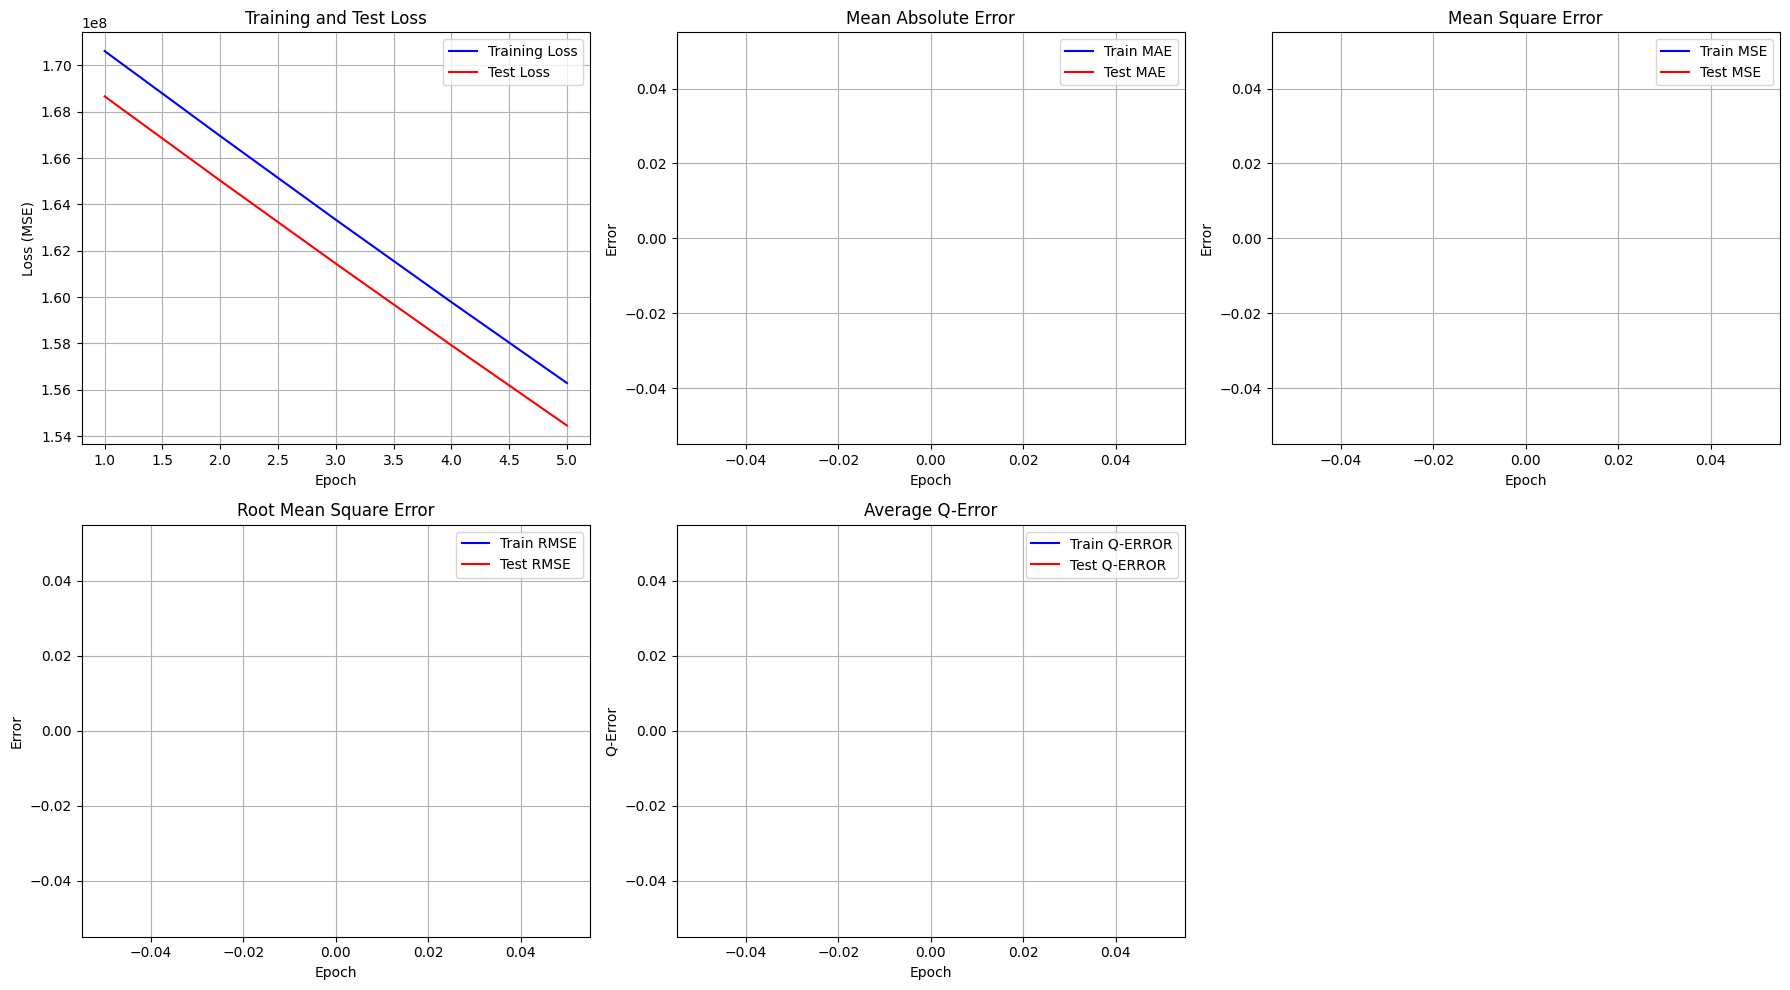

2025-09-30 11:36:30,602 - fice_training - INFO - Training metrics plot saved to: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs/training_metrics.png
2025-09-30 11:36:30,603 - fice_training - INFO - Training curves and metrics plotted!
2025-09-30 11:36:30,603 - fice_training - INFO - Training curves and metrics plotted!


Training curves and metrics plotted!


In [22]:
# Use the new plotting function from plotting module
metrics_plot_path = log_dir / 'training_metrics.png'
fig = plotting.plot_training_metrics(
    df=full_df,
    figsize=(18, 10),
    use_log_scale=False,  # You can set this to True if you want log scale
    save_path=metrics_plot_path,
    show_plot=True
)

logger.info(f"Training metrics plot saved to: {metrics_plot_path}")
logger.info("Training curves and metrics plotted!")

## 14. Predictions vs True Values Visualization

Create scatter plots showing model predictions vs true cardinality values across all epochs.

Predictions vs True Values plot saved to: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs/predictions_vs_true_values_all_epochs.png


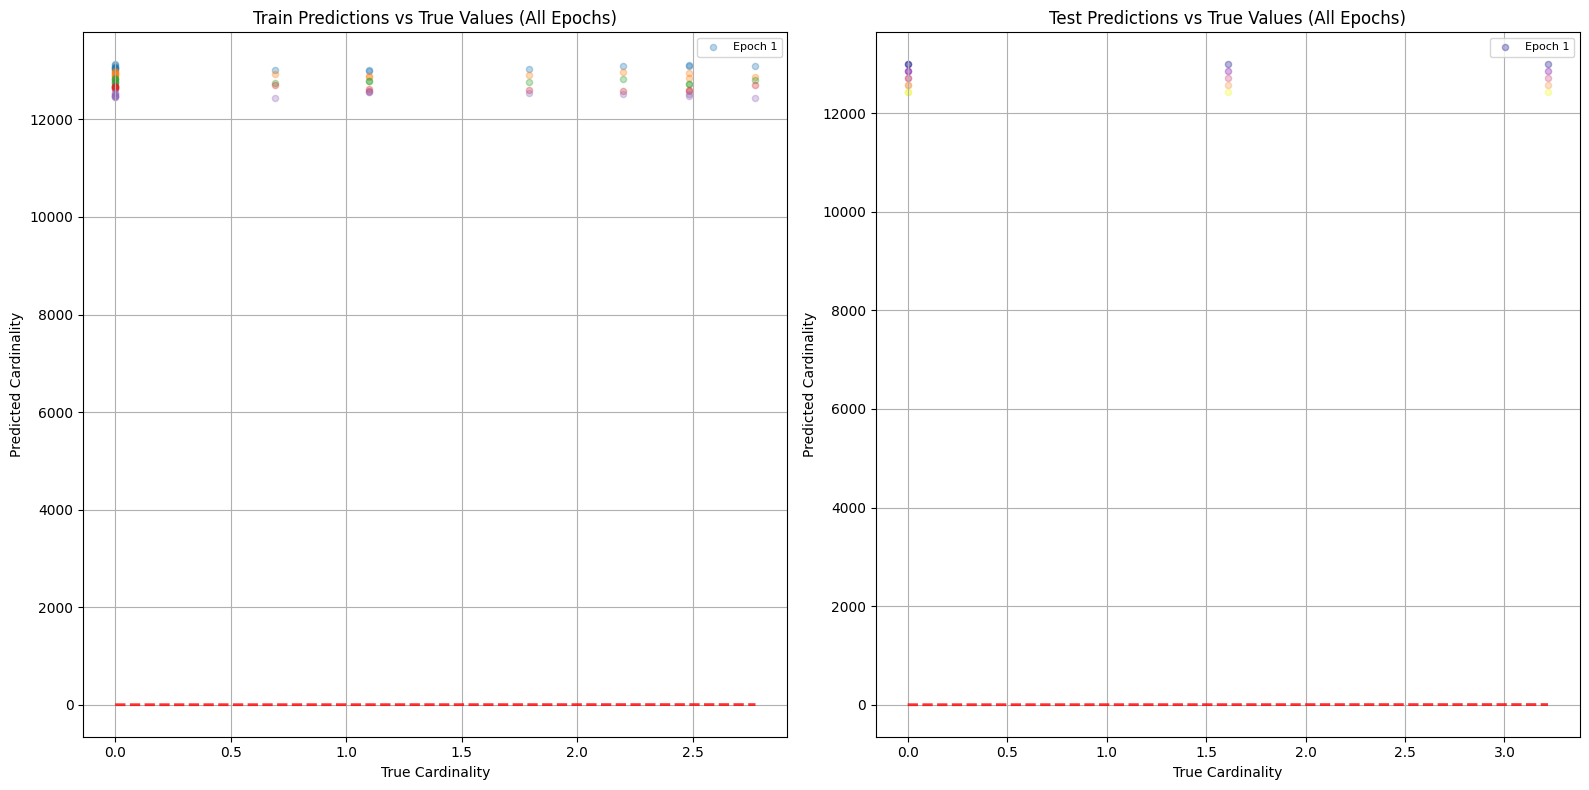

2025-09-30 11:36:30,869 - fice_training - INFO - Predictions vs True Values plot saved to: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/run_2025-09-30_11-34-38/logs/predictions_vs_true_values_all_epochs.png
2025-09-30 11:36:30,870 - fice_training - INFO - Predictions vs True Values across all epochs plotted!
2025-09-30 11:36:30,870 - fice_training - INFO - Predictions vs True Values across all epochs plotted!


Predictions vs True Values across all epochs plotted!


In [23]:
# Use the new plotting function for predictions vs true values
predictions_plot_path = log_dir / 'predictions_vs_true_values_all_epochs.png'

fig = plotting.plot_predictions_vs_true_values(
    train_predictions_log=train_predictions_log,
    train_true_values_log=train_true_values_log,
    test_predictions_log=test_predictions_log,
    test_true_values_log=test_true_values_log,
    figsize=(16, 8),
    max_points_per_epoch=50,
    random_seed=config["seed"],
    save_path=predictions_plot_path,
    show_plot=True
)

logger.info(f"Predictions vs True Values plot saved to: {predictions_plot_path}")
logger.info("Predictions vs True Values across all epochs plotted!")

## 15. Training Summary

Display final training results and saved artifacts.

In [24]:
logger.info("=" * 60)
logger.info("TRAINING COMPLETED SUCCESSFULLY")
logger.info("=" * 60)
logger.info(f"Configuration used:")
for key, value in config.items():
    logger.info(f"  {key}: {value}")

logger.info(f"\nTraining Results:")
logger.info(f"  Total epochs trained: {len(train_losses)}")
logger.info(f"  Best test loss: {best_test_loss:.6f}")
logger.info(f"  Final train loss: {train_losses[-1]:.6f}")
logger.info(f"  Final test loss: {test_losses[-1]:.6f}")
logger.info(f"  Final train MAE: {train_mae[-1]:.6f}")
logger.info(f"  Final test MAE: {test_mae[-1]:.6f}")
logger.info(f"  Final train Q-Error: {train_q_error[-1]:.6f}")
logger.info(f"  Final test Q-Error: {test_q_error[-1]:.6f}")

logger.info(f"\nSaved Artifacts:")
logger.info(f"  Run directory: {run_dir}")
logger.info(f"  Best model: {checkpoint_dir / 'best_model.pt'}")
logger.info(f"  Training metrics CSV: {log_dir / 'training_curves.csv'}")
logger.info(f"  Training metrics plot: {log_dir / 'training_metrics.png'}")
logger.info(f"  Predictions plot: {log_dir / 'predictions_vs_true_values_all_epochs.png'}")
logger.info(f"  Log files: {log_dir}")

logger.info("\n" + "=" * 60)
logger.info("Training notebook execution completed!")
logger.info("=" * 60)

2025-09-30 11:36:30,874 - fice_training - INFO - ============================================================
2025-09-30 11:36:30,875 - fice_training - INFO - TRAINING COMPLETED SUCCESSFULLY
2025-09-30 11:36:30,875 - fice_training - INFO - ============================================================
2025-09-30 11:36:30,875 - fice_training - INFO - Configuration used:
2025-09-30 11:36:30,876 - fice_training - INFO -   data_root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf
2025-09-30 11:36:30,876 - fice_training - INFO -   queries_root: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_queries
2025-09-30 11:36:30,876 - fice_training - INFO -   epochs: 5
2025-09-30 11:36:30,876 - fice_training - INFO -   batch_size: 1
2025-09-30 11:36:30,877 - fice_training - INFO -   learning_rate: 1e-05
2025-09-30 11:36:30,877 - fice_training - INFO -   weight_decay: 0.0
2025-09-30 11:36:30,877 - fice_training - INFO -   train_ratio: 0.8
2025-09-30 11:36:30,877 - fice_training - IN